# comparaison des methodes ADAPT : shift noise

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "noise"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,0.049661,0.951031,0.915226,False
1,sans adaptation,0.50,0.033010,0.071310,0.951031,0.880870,False
2,sans adaptation,1.00,0.033010,0.126432,0.951031,0.800064,False
3,CORAL,0.25,0.033010,1.993986,0.951031,-2.403843,False
4,CORAL,0.50,0.033010,2.011055,0.951031,-2.359634,False
5,CORAL,1.00,0.033010,2.060135,0.951031,-2.257850,False
6,SA,0.25,0.033010,0.696778,0.951031,-0.189438,False
7,SA,0.50,0.033010,0.717602,0.951031,-0.198813,False
8,SA,1.00,0.033010,0.771074,0.951031,-0.219359,False
9,TCA,0.25,4.374075,4.451451,-5.488725,-6.598873,False


## Comparaison (r2 cible)

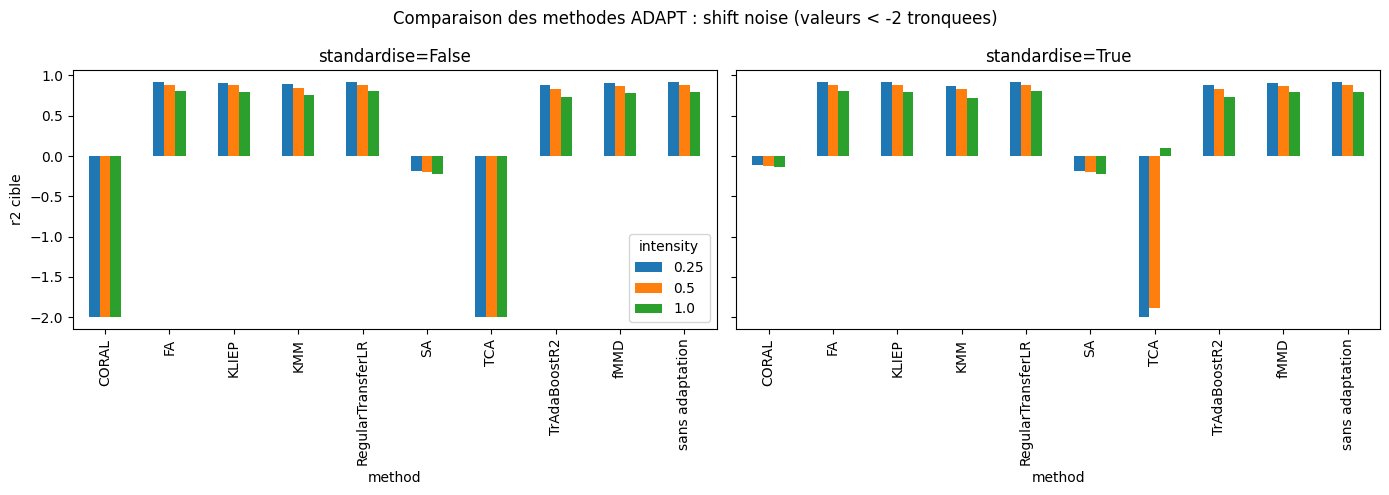

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                       r2_target             \
intensity              0.25       0.50       1.00      0.25       0.50   
method                                                                   
CORAL              0.951031   0.951031   0.951031 -2.403843  -2.359634   
FA                 0.950973   0.950900   0.950666  0.917381   0.884355   
KLIEP              0.946072   0.946090   0.946173  0.911307   0.876187   
KMM                0.931776   0.931237   0.930769  0.888889   0.849666   
RegularTransferLR  0.947459   0.946319   0.941354  0.917412   0.884229   
SA                 0.951031   0.951031   0.951031 -0.189438  -0.198813   
TCA               -5.488725 -14.319605 -11.545211 -6.598873 -16.557907   
TrAdaBoostR2       0.926903   0.925010   0.918868  0.882318   0.837051   
fMMD               0.948867   0.948867   0.948867  0.908929   0.872465   
sans adaptation    0.951031   0.951031   0.951031  0.915226   0.880870   

                              
intensity               1.00  
method                        
CORAL              -2.257850  
FA                  0.808263  
KLIEP               0.793685  
KMM                 0.761561  
RegularTransferLR   0.807515  
SA                 -0.219359  
TCA               -13.186961  
TrAdaBoostR2        0.734668  
fMMD                0.786702  
sans adaptation     0.800064

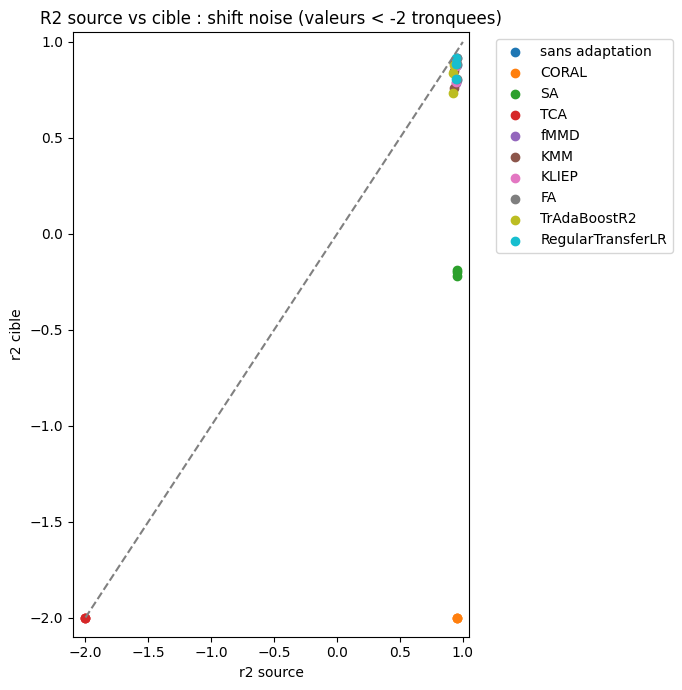

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()